In [28]:
import math
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint, odeint_adjoint
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

$$
\begin{cases}
\dot{x} = -4x(x^2-1)\\
\dot{y} = -4y(y^2-1)
\end{cases}
$$

In [29]:
class GradientSystem(nn.Module):
   def __init__(self):
        super().__init__()

       

   def forward(self,t,z):
        x, y = z[...,0], z[...,1]
        dx = -4*x*(x**2-1)
        dy = -4*y*(y**2-1)

        return torch.stack([dx,dy], dim= -1)

In [30]:
def makeDataSet(n_traj=200, T=3.0, step=60, noise_std=0.02):
    gt=GradientSystem().to(device)
    t=torch.linspace(0.0, T, step, device=device)

    x0 = 1.2*(2*torch.rand(n_traj)-1)
    y0 = 1.2*(2*torch.rand(n_traj)-1)
    z0=torch.stack([x0,y0], dim=-1)

    with torch.no_grad():
        z_traj= odeint(gt, z0, t, method = "dopri5")
        z_traj=z_traj.transpose(0,1).contiguous()
        if noise_std > 0:
             z_traj = z_traj + noise_std * torch.randn_like(z_traj)
    return z0, t, z_traj

In [31]:
z0_all, t_eval, Z_all = makeDataSet(n_traj=400, T=1.0, step=100, noise_std=0.01)
N=z0_all.size(0)
perm=torch.randperm(N)


train_idx=perm[: int(0.8*N)] #перемешанные индексы 
test_idx=perm[int(0.8*N):]

z0_train, z0_test = z0_all[train_idx], z0_all[test_idx]
Z_train, Z_test = Z_all[train_idx], Z_all[test_idx]

train_load = DataLoader(TensorDataset(z0_train, Z_train), batch_size=64, shuffle=True)
test_load = DataLoader(TensorDataset(z0_test, Z_test), batch_size=128, shuffle=False)



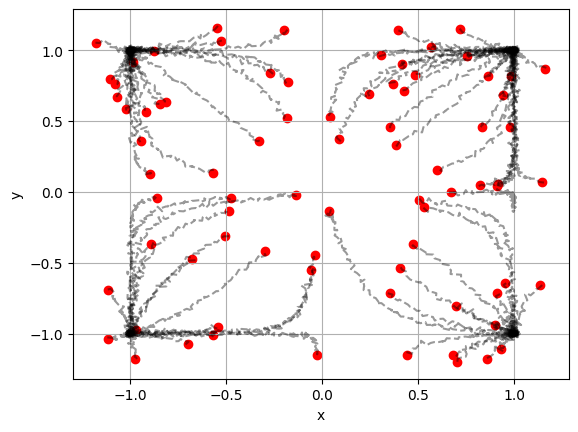

In [32]:


for z0_batch, Z_batch in test_load:
    for i in range (Z_batch.size(0)):
        x = Z_batch[i,:,0].cpu().numpy()
        y = Z_batch[i,:,1].cpu().numpy()
        plt.plot(x,y,'k--',alpha=0.4)

   
    plt.scatter(z0_batch[:, 0].cpu().numpy(),
                z0_batch[:, 1].cpu().numpy(),
                color='red')
    break

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()
        

In [33]:
class ODEmodel(nn.Module):
    def __init__(self,state_dim=2, hidden=128, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim+(1 if time_dependent else 0)
        self.net=nn.Sequential(
            nn.Linear(in_dim, hidden),nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden,state_dim),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)
        

    def forward(self, t,z):
        if z.dim()==1:
            z = z.unsqueeze(0)
        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z
        return self.net(h)
    
class NeuralODE(nn.Module):
     def __init__(self, func, use_adjoint, rtol=1e-3, atol=1e-4, method="dopri5"):
            super().__init__()
            self.func = func
            self.use_adjoint = use_adjoint
            self.rtol = rtol
            self.atol = atol
            self.method = method


     def forward(self,z0,t):
            solver= odeint_adjoint if self.use_adjoint else odeint
            Z = solver(self.func, z0, t , rtol=self.rtol, atol=self.atol, method=self.method)
            return Z.transpose(0, 1).contiguous()



In [34]:
def mse ( z_hat, z_true):
    return torch.mean((z_hat-z_true)**2)

In [35]:
def evaluate1(model, loader, t_eval):
    model.eval()
    mse_sum, count = 0.0, 0
    with torch.no_grad():
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            mse_sum += mse(Z_pred, Z).item()*z0.size(0)
            count +=z0.size(0)
        return mse_sum/count

In [36]:
def train1(model, loader, t_eval, epochs=60, lr = 2e-4, clip_grad = 5.0, tag="NODE"):
    optim=  torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(1, epochs+1):
        model.train()
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            loss=mse(Z_pred, Z)

            optim.zero_grad()
            loss.backward()
            if clip_grad:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            optim.step()
            
        if ep %12 ==0:
            tr = evaluate1(model, train_load, t_eval)
            te = evaluate1(model, test_load, t_eval)

            print(f"[{tag}] Epoch {ep:03d} | train {tr:.6f} | test {te:.6f}")
    
    return model




In [37]:
func_reg = ODEmodel().to(device)
node_reg = NeuralODE(func_reg, use_adjoint=False).to(device)


print("Training Neural ODE (regular)...")
node_reg = train1(node_reg, train_load, t_eval, tag="REG")


func_adj = ODEmodel().to(device)
node_adj = NeuralODE(func_adj, use_adjoint=True).to(device)

print("\nTraining Neural ODE (adjoint)...")
node_adj = train1(node_adj, train_load, t_eval, tag="ADJ")

print("\n=== Final MSE ===")
print("Regular :", evaluate1(node_reg, train_load, t_eval), evaluate1(node_reg, test_load,  t_eval))
print("Adjoint :", evaluate1(node_adj, train_load, t_eval), evaluate1(node_adj, test_load,  t_eval))

Training Neural ODE (regular)...


[REG] Epoch 012 | train 0.116880 | test 0.103468
[REG] Epoch 024 | train 0.116592 | test 0.103152
[REG] Epoch 036 | train 0.116275 | test 0.102876
[REG] Epoch 048 | train 0.115849 | test 0.102584
[REG] Epoch 060 | train 0.115275 | test 0.102280

Training Neural ODE (adjoint)...
[ADJ] Epoch 012 | train 0.116611 | test 0.103017
[ADJ] Epoch 024 | train 0.116255 | test 0.102530
[ADJ] Epoch 036 | train 0.115749 | test 0.101989
[ADJ] Epoch 048 | train 0.114985 | test 0.101767
[ADJ] Epoch 060 | train 0.113852 | test 0.100711

=== Final MSE ===
Regular : 0.11527456343173981 0.1022801548242569
Adjoint : 0.11385206282138824 0.10071123391389847
